
image 1/1 /home/wiacker/machinevision/obraz_ulica.jpg: 480x640 6 persons, 1 bicycle, 5 cars, 1 dog, 2 handbags, 32.1ms
Speed: 10.5ms preprocess, 32.1ms inference, 4.7ms postprocess per image at shape (1, 3, 480, 640)


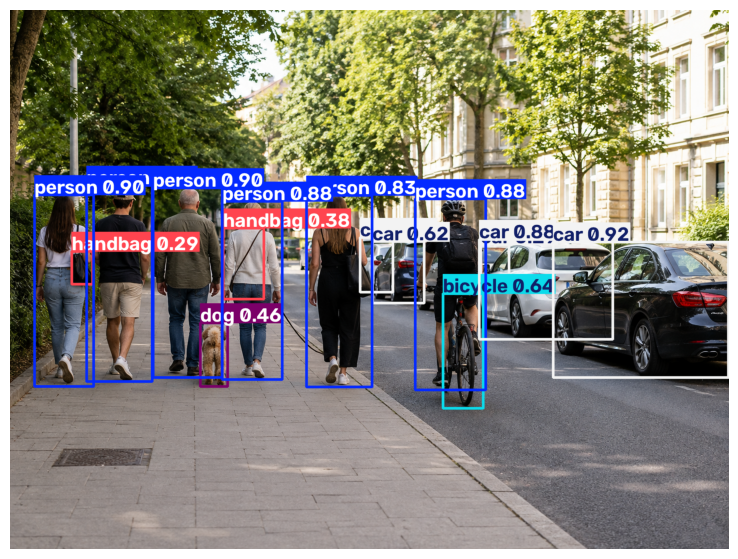

In [7]:
from ultralytics import YOLO
import cv2
import numpy as np
import matplotlib.pyplot as plt

model = YOLO("yolov8n.pt")

wyniki = model("obraz_ulica.jpg")
wynik = wyniki[0]

narysowany = wynik.plot()
narysowany_rgb = cv2.cvtColor(narysowany, cv2.COLOR_BGR2RGB)

plt.figure(figsize=(12, 7))
plt.imshow(narysowany_rgb)
plt.axis("off")
plt.show()

In [ ]:
print("Liczba wykrytych obiektow:", len(wynik.boxes))
print("Przykladowe klasy modelu:", list(model.names.values())[:10])

for ramka in wynik.boxes:
    nazwa = model.names[int(ramka.cls[0])]
    pewnosc = float(ramka.conf[0])
    x1, y1, x2, y2 = ramka.xyxy[0].tolist()
    print(
        f"{nazwa}: pewnosc {pewnosc:.2f}, "
        f"ramka od ({x1:.0f}, {y1:.0f}) do ({x2:.0f}, {y2:.0f})"
    )

Liczba wykrytych obiektow: 15
Przykladowe klasy modelu: ['person', 'bicycle', 'car', 'motorcycle', 'airplane', 'bus', 'train', 'truck', 'boat', 'traffic light']
car: pewnosc 0.92, ramka od (1095, 467) do (1448, 740)
person: pewnosc 0.90, ramka od (50, 373) do (168, 758)
person: pewnosc 0.90, ramka od (288, 359) do (427, 741)
person: pewnosc 0.88, ramka od (427, 385) do (548, 744)
person: pewnosc 0.88, ramka od (154, 353) do (287, 748)
car: pewnosc 0.88, ramka od (946, 463) do (1214, 664)
person: pewnosc 0.88, ramka od (816, 381) do (958, 765)
person: pewnosc 0.83, ramka od (598, 374) do (729, 759)
bicycle: pewnosc 0.64, ramka od (872, 571) do (953, 802)
car: pewnosc 0.62, ramka od (730, 467) do (834, 590)
dog: pewnosc 0.46, ramka od (384, 631) do (439, 759)
handbag: pewnosc 0.38, ramka od (429, 439) do (511, 582)
car: pewnosc 0.35, ramka od (705, 459) do (771, 569)
car: pewnosc 0.29, ramka od (948, 473) do (1005, 534)
handbag: pewnosc 0.29, ramka od (124, 487) do (167, 552)


In [ ]:
zliczenia = {}
for ramka in wynik.boxes:
    nazwa = model.names[int(ramka.cls[0])]
    zliczenia[nazwa] = zliczenia.get(nazwa, 0) + 1

for nazwa, ile in sorted(zliczenia.items()):
    print(nazwa, ":", ile)

bicycle : 1
car : 5
dog : 1
handbag : 2
person : 6


Prog 0.1 : liczba wykryc = 17
Prog 0.5 : liczba wykryc = 10
Prog 0.8 : liczba wykryc = 8


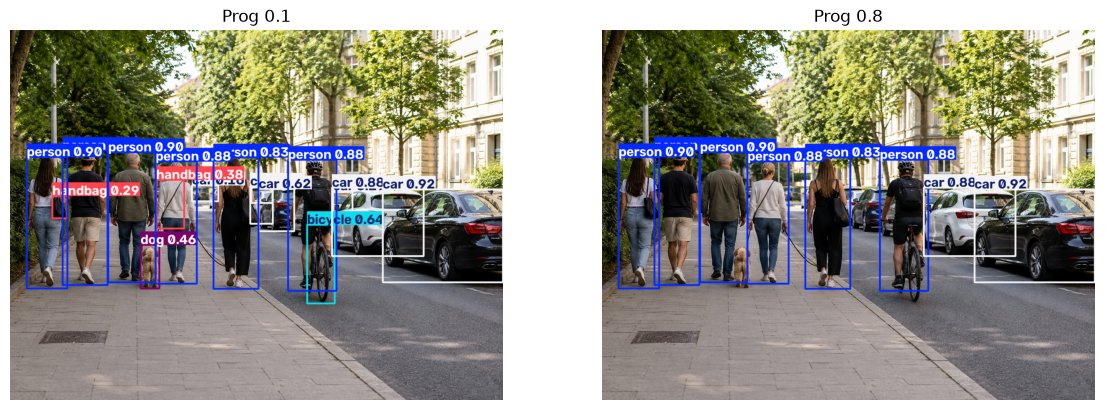

In [ ]:
for prog in [0.1, 0.5, 0.8]:
    w = model("obraz_ulica.jpg", conf=prog, verbose=False)[0]
    print("Prog", prog, ": liczba wykryc =", len(w.boxes))

w_niski = model("obraz_ulica.jpg", conf=0.1, verbose=False)[0]
w_wysoki = model("obraz_ulica.jpg", conf=0.8, verbose=False)[0]

plt.figure(figsize=(14, 5))
plt.subplot(1, 2, 1)
plt.imshow(cv2.cvtColor(w_niski.plot(), cv2.COLOR_BGR2RGB))
plt.title("Prog 0.1")
plt.axis("off")
plt.subplot(1, 2, 2)
plt.imshow(cv2.cvtColor(w_wysoki.plot(), cv2.COLOR_BGR2RGB))
plt.title("Prog 0.8")
plt.axis("off")
plt.show()

Ramki identyczne: 1.0
Ramki czesciowo nachodzace: 0.14
Ramki rozlaczne: 0.0


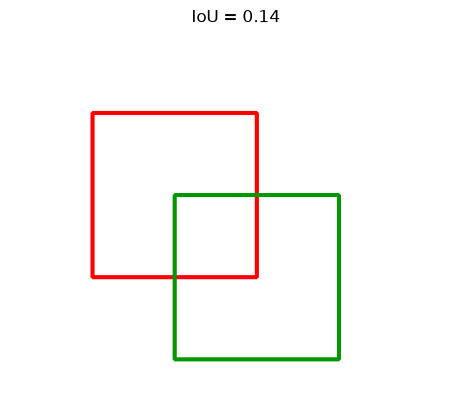

In [ ]:
def iou(a, b):
    x1 = max(a[0], b[0])
    y1 = max(a[1], b[1])
    x2 = min(a[2], b[2])
    y2 = min(a[3], b[3])
    przeciecie = max(0, x2 - x1) * max(0, y2 - y1)
    pole_a = (a[2] - a[0]) * (a[3] - a[1])
    pole_b = (b[2] - b[0]) * (b[3] - b[1])
    return przeciecie / (pole_a + pole_b - przeciecie)


ramka_a = [100, 100, 300, 300]
ramka_b = [200, 200, 400, 400]

print("Ramki identyczne:", iou(ramka_a, ramka_a))
print("Ramki czesciowo nachodzace:", round(iou(ramka_a, ramka_b), 2))
print("Ramki rozlaczne:", iou(ramka_a, [400, 400, 500, 500]))

plansza = np.full((450, 550, 3), 255, np.uint8)
cv2.rectangle(plansza, (100, 100), (300, 300), (255, 0, 0), 3)
cv2.rectangle(plansza, (200, 200), (400, 400), (0, 150, 0), 3)

plt.imshow(plansza)
plt.title("IoU = 0.14")
plt.axis("off")
plt.show()


image 1/1 /home/wiacker/machinevision/obraz_biurko.jpg: 480x640 1 cup, 1 dining table, 1 laptop, 2 mouses, 1 keyboard, 1 book, 27.6ms
Speed: 6.1ms preprocess, 27.6ms inference, 6.3ms postprocess per image at shape (1, 3, 480, 640)


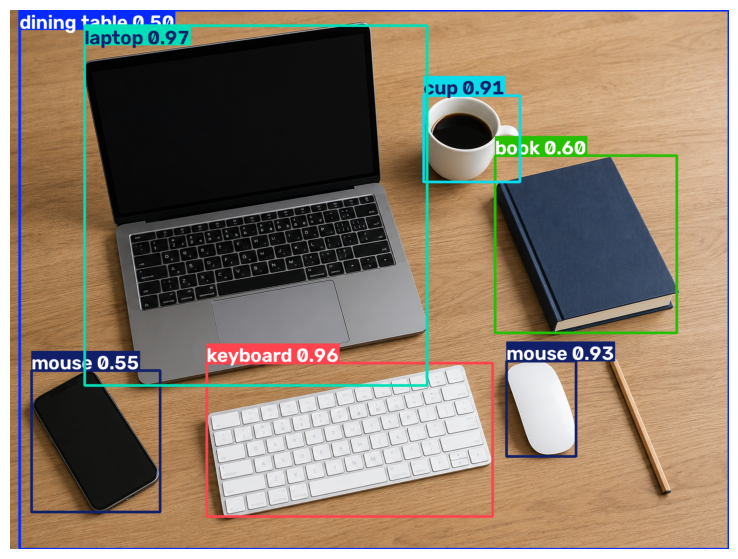

In [ ]:
w_biurko = model("obraz_biurko.jpg")[0]

plt.figure(figsize=(12, 7))
plt.imshow(cv2.cvtColor(w_biurko.plot(), cv2.COLOR_BGR2RGB))
plt.axis("off")
plt.show()

# Zadanie 1

WARNING ⚠️ 'source' is missing. Using 'source=/home/wiacker/machinevision/.venv/lib/python3.14/site-packages/ultralytics/assets'.

image 1/2 /home/wiacker/machinevision/.venv/lib/python3.14/site-packages/ultralytics/assets/bus.jpg: 640x480 4 persons, 1 bus, 1 stop sign, 79.9ms


[ WARN:0@661.908] global loadsave.cpp:278 findDecoder imread_('moje_zdjecie.jpg'): can't open/read file: check file path/integrity


image 2/2 /home/wiacker/machinevision/.venv/lib/python3.14/site-packages/ultralytics/assets/zidane.jpg: 384x640 2 persons, 1 tie, 64.4ms
Speed: 8.1ms preprocess, 72.2ms inference, 7.1ms postprocess per image at shape (1, 3, 384, 640)
bus 0.87
person 0.87
person 0.85
person 0.83
person 0.26
stop sign 0.26
['person', 'bicycle', 'car', 'motorcycle', 'airplane', 'bus', 'train', 'truck', 'boat', 'traffic light', 'fire hydrant', 'stop sign', 'parking meter', 'bench', 'bird', 'cat', 'dog', 'horse', 'sheep', 'cow', 'elephant', 'bear', 'zebra', 'giraffe', 'backpack', 'umbrella', 'handbag', 'tie', 'suitcase', 'frisbee', 'skis', 'snowboard', 'sports ball', 'kite', 'baseball bat', 'baseball glove', 'skateboard', 'surfboard', 'tennis racket', 'bottle', 'wine glass', 'cup', 'fork', 'knife', 'spoon', 'bowl', 'banana', 'apple', 'sandwich', 'orange', 'broccoli', 'carrot', 'hot dog', 'pizza', 'donut', 'cake', 'chair', 'couch', 'potted plant', 'bed', 'dining table', 'toilet', 'tv', 'laptop', 'mouse', 're

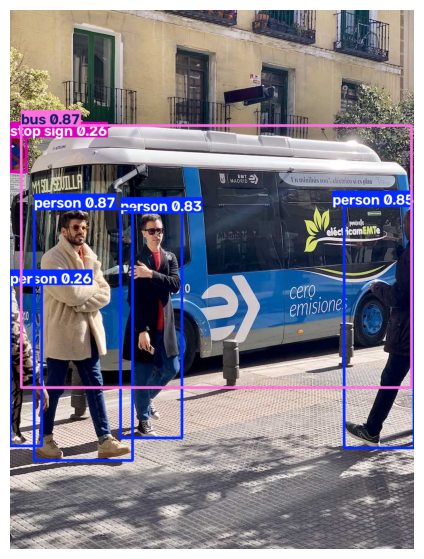

In [ ]:
obraz = cv2.imread("moje_zdjecie.jpg")

w = model(obraz)[0]

for ramka in w.boxes:
    print(model.names[int(ramka.cls[0])], round(float(ramka.conf[0]), 2))

print(list(model.names.values()))

plt.figure(figsize=(12, 7))
plt.imshow(cv2.cvtColor(w.plot(), cv2.COLOR_BGR2RGB))
plt.axis("off")
plt.show()

# Zadanie 2

Prog 0.05 : liczba wykryc = 19
Prog 0.25 : liczba wykryc = 15
Prog 0.7 : liczba wykryc = 8


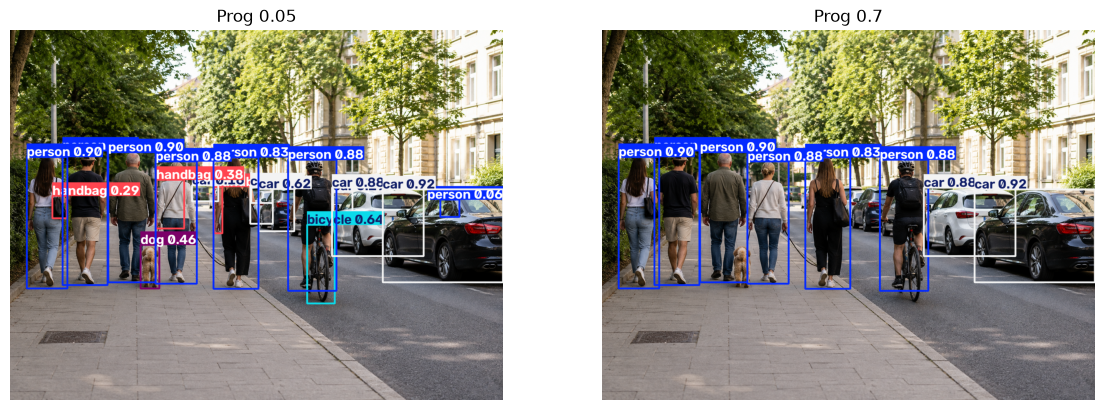

In [ ]:
obraz = cv2.imread("obraz_ulica.jpg")

for prog in [0.05, 0.25, 0.7]:
    w = model(obraz, conf=prog, verbose=False)[0]
    print("Prog", prog, ": liczba wykryc =", len(w.boxes))

w_niski = model(obraz, conf=0.05, verbose=False)[0]
w_wysoki = model(obraz, conf=0.7, verbose=False)[0]

plt.figure(figsize=(14, 5))
plt.subplot(1, 2, 1)
plt.imshow(cv2.cvtColor(w_niski.plot(), cv2.COLOR_BGR2RGB))
plt.title("Prog 0.05")
plt.axis("off")
plt.subplot(1, 2, 2)
plt.imshow(cv2.cvtColor(w_wysoki.plot(), cv2.COLOR_BGR2RGB))
plt.title("Prog 0.7")
plt.axis("off")
plt.show()

# Zadanie 3

ramka: 1094 467 1447 740
wycinek: (273, 353, 3)


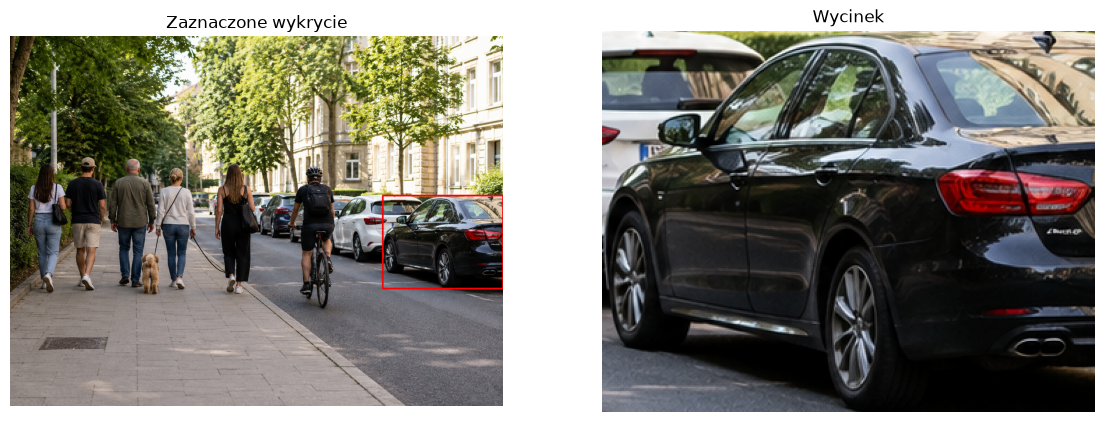

In [ ]:
obraz = cv2.imread("obraz_ulica.jpg")

w = model(obraz, verbose=False)[0]

najlepsza = w.boxes[0]
for ramka in w.boxes:
    if float(ramka.conf[0]) > float(najlepsza.conf[0]):
        najlepsza = ramka

x1, y1, x2, y2 = [int(v) for v in najlepsza.xyxy[0].tolist()]
print("ramka:", x1, y1, x2, y2)

wycinek = obraz[y1:y2, x1:x2]
print("wycinek:", wycinek.shape)

cv2.imwrite("wyciety_obiekt.png", wycinek)

zaznaczony = obraz.copy()
cv2.rectangle(zaznaczony, (x1, y1), (x2, y2), (0, 0, 255), 3)

plt.figure(figsize=(14, 6))
plt.subplot(1, 2, 1)
plt.imshow(cv2.cvtColor(zaznaczony, cv2.COLOR_BGR2RGB))
plt.title("Zaznaczone wykrycie")
plt.axis("off")
plt.subplot(1, 2, 2)
plt.imshow(cv2.cvtColor(wycinek, cv2.COLOR_BGR2RGB))
plt.title("Wycinek")
plt.axis("off")
plt.show()

# Zadanie 4

osoby: 6, samochody: 5


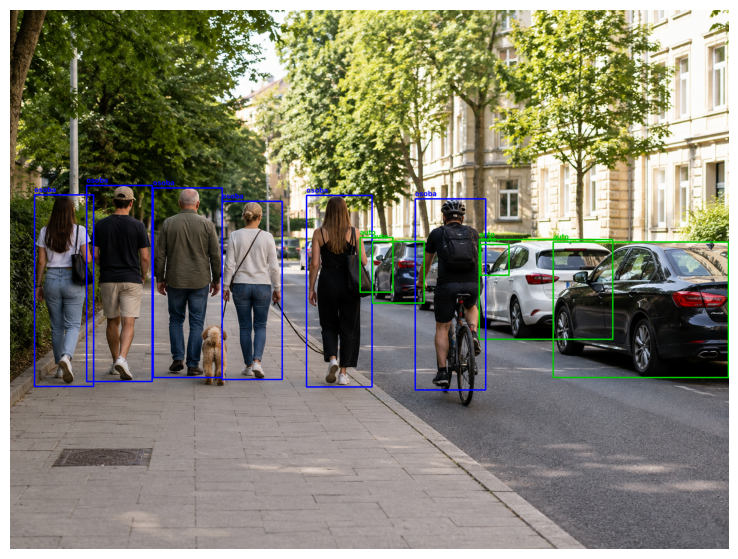

In [ ]:
obraz = cv2.imread("obraz_ulica.jpg")

w = model(obraz, verbose=False)[0]

zaznaczony = obraz.copy()
osoby = 0
samochody = 0
for ramka in w.boxes:
    nazwa = model.names[int(ramka.cls[0])]
    x1, y1, x2, y2 = [int(v) for v in ramka.xyxy[0].tolist()]
    if nazwa == "person":
        osoby = osoby + 1
        cv2.rectangle(zaznaczony, (x1, y1), (x2, y2), (255, 0, 0), 2)
        cv2.putText(
            zaznaczony,
            "osoba",
            (x1, y1 - 5),
            cv2.FONT_HERSHEY_SIMPLEX,
            0.5,
            (255, 0, 0),
            2,
        )
    if nazwa == "car":
        samochody = samochody + 1
        cv2.rectangle(zaznaczony, (x1, y1), (x2, y2), (0, 200, 0), 2)
        cv2.putText(
            zaznaczony,
            "auto",
            (x1, y1 - 5),
            cv2.FONT_HERSHEY_SIMPLEX,
            0.5,
            (0, 200, 0),
            2,
        )

print(f"osoby: {osoby}, samochody: {samochody}")

plt.figure(figsize=(12, 7))
plt.imshow(cv2.cvtColor(zaznaczony, cv2.COLOR_BGR2RGB))
plt.axis("off")
plt.show()

# Zadanie 5

nano  : liczba wykryc = 15 , czas: {'preprocess': 916.8512910000572, 'inference': 29.072323000036704, 'postprocess': 4.402456999969218}
   car 0.92
   person 0.9
   person 0.9
   person 0.88
   person 0.88
   car 0.88
   person 0.88
   person 0.83
   bicycle 0.64
   car 0.62
   dog 0.46
   handbag 0.38
   car 0.35
   car 0.29
   handbag 0.29
small : liczba wykryc = 19 , czas: {'preprocess': 3.8372919998437283, 'inference': 53.36767599987979, 'postprocess': 4.157742999950642}
   car 0.93
   person 0.92
   car 0.91
   person 0.9
   person 0.88
   person 0.88
   person 0.88
   person 0.87
   car 0.83
   handbag 0.8
   dog 0.79
   bicycle 0.71
   car 0.61
   backpack 0.58
   car 0.53
   handbag 0.5
   car 0.4
   car 0.4
   handbag 0.36


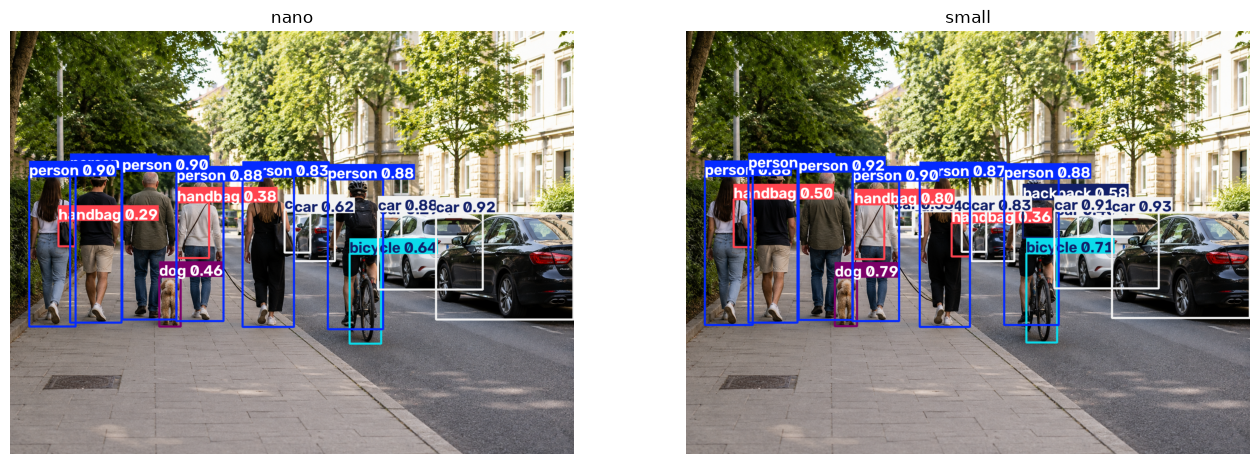

In [ ]:
obraz = cv2.imread("obraz_ulica.jpg")

model_s = YOLO("yolov8s.pt")

w_n = model(obraz, verbose=False)[0]
w_s = model_s(obraz, verbose=False)[0]

print("nano  : liczba wykryc =", len(w_n.boxes), ", czas:", w_n.speed)
for ramka in w_n.boxes:
    print("  ", model.names[int(ramka.cls[0])], round(float(ramka.conf[0]), 2))

print("small : liczba wykryc =", len(w_s.boxes), ", czas:", w_s.speed)
for ramka in w_s.boxes:
    print("  ", model_s.names[int(ramka.cls[0])], round(float(ramka.conf[0]), 2))

plt.figure(figsize=(16, 6))
plt.subplot(1, 2, 1)
plt.imshow(cv2.cvtColor(w_n.plot(), cv2.COLOR_BGR2RGB))
plt.title("nano")
plt.axis("off")
plt.subplot(1, 2, 2)
plt.imshow(cv2.cvtColor(w_s.plot(), cv2.COLOR_BGR2RGB))
plt.title("small")
plt.axis("off")
plt.show()

WARNING ⚠️ 'source' is missing. Using 'source=/home/wiacker/machinevision/.venv/lib/python3.14/site-packages/ultralytics/assets'.
obraz_ulica.jpg {'car': 5, 'person': 6, 'bicycle': 1, 'dog': 1, 'handbag': 2}
obraz_biurko.jpg {'laptop': 1, 'keyboard': 1, 'mouse': 2, 'cup': 1, 'book': 1, 'dining table': 1}
moje_zdjecie.jpg {'bus': 1, 'person': 4, 'stop sign': 1}


[ WARN:0@1122.378] global loadsave.cpp:278 findDecoder imread_('moje_zdjecie.jpg'): can't open/read file: check file path/integrity


WARNING ⚠️ 'source' is missing. Using 'source=/home/wiacker/machinevision/.venv/lib/python3.14/site-packages/ultralytics/assets'.


[ WARN:0@1122.812] global loadsave.cpp:278 findDecoder imread_('moje_zdjecie.jpg'): can't open/read file: check file path/integrity


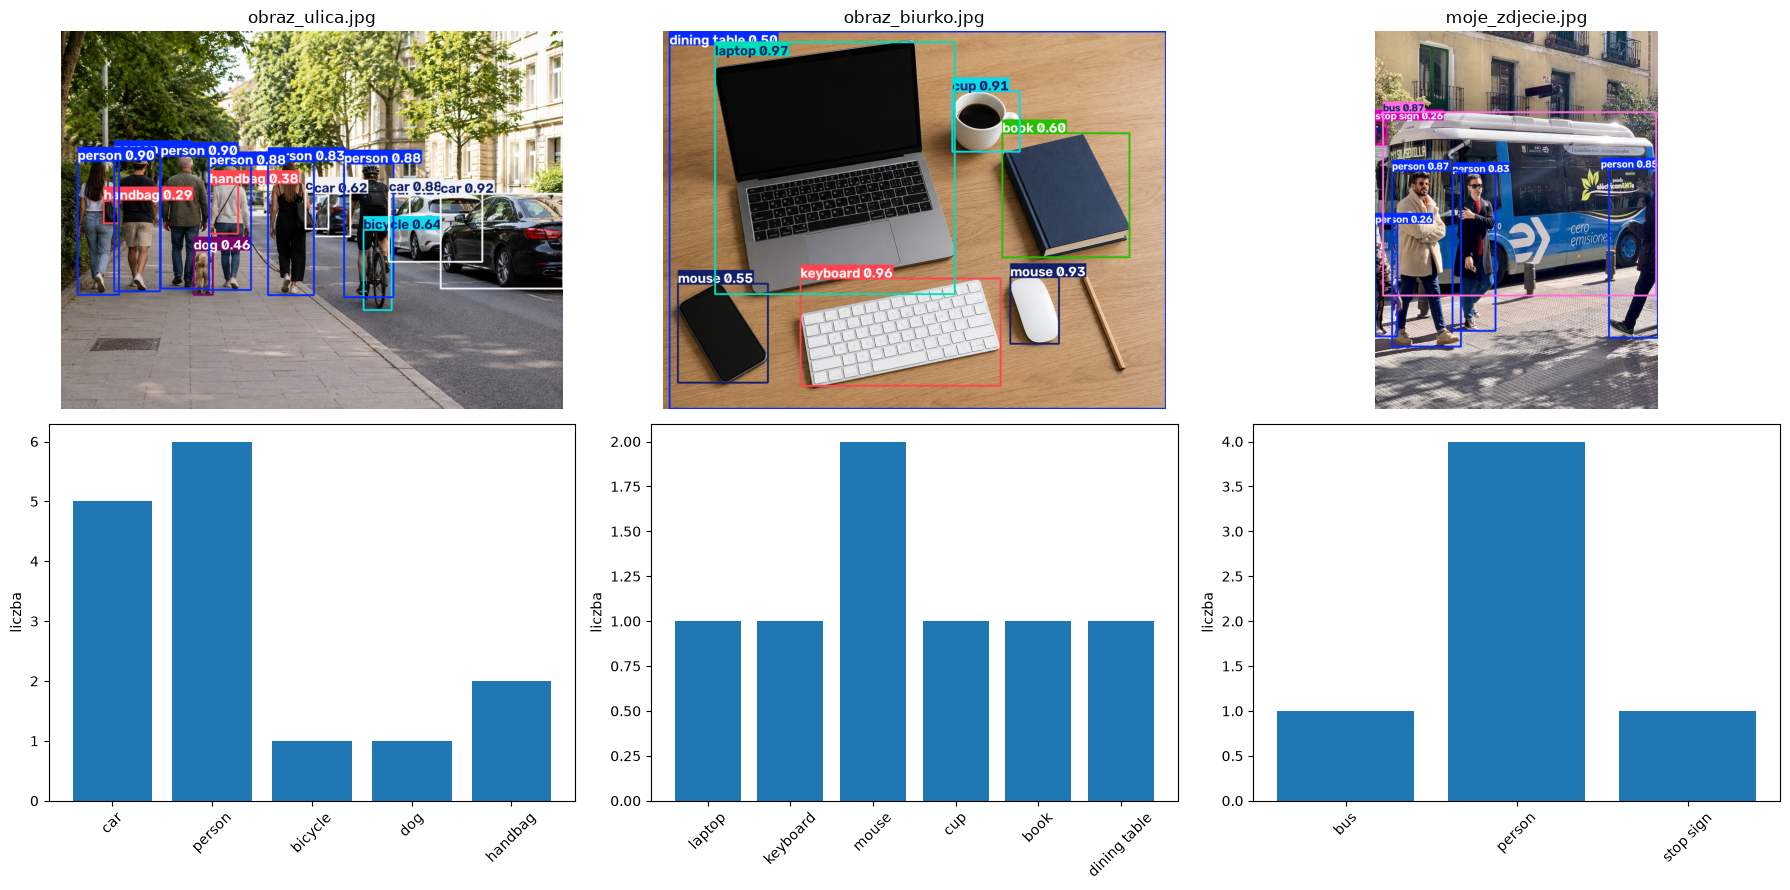

In [22]:
sciezki = ["obraz_ulica.jpg", "obraz_biurko.jpg", "moje_zdjecie.jpg"]


def licznik(sciezki):
    wyniki = {}
    for sciezka in sciezki:
        obraz = cv2.imread(sciezka)
        w = model(obraz, verbose=False)[0]
        zliczenia = {}
        for ramka in w.boxes:
            nazwa = model.names[int(ramka.cls[0])]
            zliczenia[nazwa] = zliczenia.get(nazwa, 0) + 1
        wyniki[sciezka] = zliczenia
    return wyniki


wyniki = licznik(sciezki)

for sciezka, zliczenia in wyniki.items():
    print(sciezka, zliczenia)

plt.figure(figsize=(18, 9))
for i, sciezka in enumerate(sciezki):
    obraz = cv2.imread(sciezka)
    w = model(obraz, verbose=False)[0]

    plt.subplot(2, 3, i + 1)
    plt.imshow(cv2.cvtColor(w.plot(), cv2.COLOR_BGR2RGB))
    plt.title(sciezka)
    plt.axis("off")

    plt.subplot(2, 3, i + 4)
    plt.bar(list(wyniki[sciezka].keys()), list(wyniki[sciezka].values()))
    plt.xticks(rotation=45)
    plt.ylabel("liczba")

plt.tight_layout()
plt.show()